# Real-vs-fake human expert study -- 200 images, 3 sources

The human rater experiment from the paper, including 200 mitotic figures, blinded and shuffled into one folder for a SWAN study, drawn from three sources:

| source | n | what it tests |
|---|---|---|
| `real` | 100 | genuine images (held out from the GAN's own training split) |
| `gan_from_real_mask` | 50 | GAN reconstruction from a *real* mask  |
| `gan_from_simulator_mask` | 50 | GAN generation from a *synthetic* mask, across the same 4 classes the phase classifier trains on (prometaphase/metaphase/ring_shape/anaphase_telophase), sampled the same way the real synthetic training set is |

**Output** (under `OUT_DIR`):
- `images/stim_####.png` -- the blinded stimuli; upload this folder to SWAN
- `answer_key.csv` --  the ground truth table `study_id,is_real,source,original_filename,phase,mechanism,tilt_deg,class`
- `masked_context/stim_####.png` / `masks/stim_####.png` / `original/
  stim_####.png` -- masked context information (complete patch with ellipse cropout) corresponding to images in 
  `images/` for direct cross-reference.

A scoring cell at the end reads a SWAN results export and reports accuracy pooled and per rater. Further, it reports it broken down by which of the three sources a stimulus actually came from.

**Requirements: Install the notebooks extra first:** (`.venv/bin/pip install -e ".[notebooks]"`).


In [ ]:
import csv
import shutil
import sys
from pathlib import Path

import numpy as np
import torch
from PIL import Image, ImageDraw

from mitosim.phases import anaphase, metaphase, prometaphase, telophase
from mitosim.render.inpaint import list_context_images, load_context_image, load_context_mask, pick_context_image
from mitosim.render.match_context import load_ellipse_db, pick_bucketed_context_image, transform_image

sys.path.insert(0, "../experiments")  # needed for gan_context_encoder.py, which lives at the repo root, not inside mitosim/
from gan_context_encoder import PairedImageMaskDataset, UNetGenerator, build_sample, split_dataset

# The real synthetic-training-set generator, reused directly (not
# reimplemented) so the simulator-mask stimuli below are drawn from
# exactly the same distribution the phase classifier actually trains on.
sys.path.insert(0, "../experiments/data")
import generate_synthetic as gs

## Parameters


In [ ]:
REAL_IMAGES_DIR = "../weights/context_images"  
REAL_MASKS_DIR = "../weights/context_masks"
CHECKPOINT_PATH = "../weights/checkpoint_best.pt"  # weights of best model
IMAGE_SIZE = 128

VAL_FRACTION = 0.1  # validation fraction, must match training
VAL_SEED = 0        # seed used in data split, must match training
POOL_SHUFFLE_SEED = 4821  # used for splitting the test set

N_REAL = 100 # number of real images
N_GAN_FROM_REAL_MASK = 50 # number of GAN-generated images from real masks

# Same 4 classes and sampling as the real synthetic training set
# (experiments/data/generate_synthetic.py, reused directly above): random
# orientation for prometaphase/anaphase_telophase, tilt sampled from a
# range and hollowness-rejection-sampled for metaphase/ring_shape -- not
# hand-picked orientations, so these stimuli are representative of what
# the classifier actually trains on, not a curated "this looks right" set.
N_PER_CLASS = {"prometaphase": 13, "metaphase": 13, "ring_shape": 12, "anaphase_telophase": 12}
CLASSES = tuple(N_PER_CLASS)
ATTEMPT_MULTIPLIER = {"prometaphase": 20, "anaphase_telophase": 20, "metaphase": 10, "ring_shape": 400}

CONTEXT = "matched"  # "matched" | "random" | an exact filename from weights/context_images/

SHUFFLE_SEED = 70133  # independent of the above -- just for blinding stimulus order
OUT_DIR = Path("../results/human_eval_200")
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
BASE_SEED = 615000  # seeds for the simulator-mask group draw from BASE_SEED, BASE_SEED+1, ...

## Load the real corpus's held-out split, and the trained generator

Same split the training run itself used (`split_dataset`) -- `real` and
`gan_from_real_mask` below only ever draw from `val_dataset`, never
`train_dataset`.

In [3]:
full_dataset = PairedImageMaskDataset(REAL_IMAGES_DIR, REAL_MASKS_DIR, image_size=IMAGE_SIZE)
_, val_dataset = split_dataset(full_dataset, VAL_FRACTION, VAL_SEED)
print(f"{len(full_dataset)} paired samples -> {len(val_dataset)} held out for validation (seed={VAL_SEED})")

n_needed = N_REAL + N_GAN_FROM_REAL_MASK
if n_needed > len(val_dataset):
    raise ValueError(f"need {n_needed} held-out images (N_REAL + N_GAN_FROM_REAL_MASK) but only {len(val_dataset)} are held out")

pool_rng = np.random.default_rng(POOL_SHUFFLE_SEED)
pool_order = pool_rng.permutation(len(val_dataset))
real_indices = pool_order[:N_REAL]
gan_real_mask_indices = pool_order[N_REAL : N_REAL + N_GAN_FROM_REAL_MASK]
print(f"{len(real_indices)} held-out images -> 'real' group, {len(gan_real_mask_indices)} (disjoint) -> 'gan_from_real_mask' group")


def original_filename(idx: int) -> str:
    # val_dataset is a plain Subset(full_dataset) here (no further capping)
    return full_dataset.filenames[val_dataset.indices[idx]]

2638 paired samples -> 264 held out for validation (seed=0)
100 held-out images -> 'real' group, 50 (disjoint) -> 'gan_from_real_mask' group


In [4]:
checkpoint_path = Path(CHECKPOINT_PATH)
if not checkpoint_path.is_file():
    checkpoint_path = checkpoint_path.with_name("checkpoint.pt")
ckpt = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
G = UNetGenerator().to(DEVICE)
G.load_state_dict(ckpt["G"])
G.eval()
print(f"loaded {checkpoint_path} (epoch {ckpt.get('epoch', '?')})")

loaded ../weights/checkpoint_best.pt (epoch 154)


## Group 1 + 2: real images, and the GAN reconstructing real masks

Both come straight out of the held-out split -- `to_img` matches
`gan_context_encoder.py`'s own denormalisation exactly.

In [5]:
def to_img(t: torch.Tensor) -> Image.Image:
    arr = ((t.clamp(-1, 1) + 1) * 127.5).byte().cpu().numpy()
    return Image.fromarray(np.transpose(arr, (1, 2, 0)))


def to_mask_img(hole_mask: torch.Tensor) -> Image.Image:
    return Image.fromarray((hole_mask[0].cpu().numpy() * 255).astype(np.uint8))


real_items = []
for idx in real_indices:
    sample = val_dataset[int(idx)]
    real_items.append({"image": to_img(sample.real), "original_filename": original_filename(int(idx))})
print(f"rendered {len(real_items)} real images")

gan_real_mask_items = []
with torch.no_grad():
    for idx in gan_real_mask_indices:
        sample = val_dataset[int(idx)]
        fake = G(sample.context_input.unsqueeze(0).to(DEVICE))[0]
        # Reference-only (researcher-side, not part of the blind study):
        # the white-filled cropout actually fed to G (context_input's first
        # 3 channels) and the chromosome/chromatin mask that conditioned the
        # generation (context_input's 5th channel, Sample.context_input's
        # docstring) -- here that's just the photo's own real segmentation
        # mask, since PairedImageMaskDataset pairs them by identical filename.
        gan_real_mask_items.append({
            "image": to_img(fake), "original_filename": original_filename(int(idx)),
            "masked_context": to_img(sample.context_input[:3]), "mask": to_mask_img(sample.context_input[4:5]),
            "original": to_img(sample.real),
        })
print(f"rendered {len(gan_real_mask_items)} GAN-from-real-mask images")

rendered 100 real images


rendered 50 GAN-from-real-mask images


## Group 3: GAN generating from simulator masks

Mask sampling below reuses `experiments/data/generate_synthetic.py`'s own
low-level functions (`sectioned`, `_sectioned_mask`, `hollowness_of`,
`optics_mask`, `jittered`, `BASE_PARAMS`/`RING_PARAMS`) directly, rather
than a separate hand-picked set of fixed orientations -- so a stimulus
labelled e.g. `ring_shape` here was drawn exactly the way a `ring_shape`
training example is, not a scenario chosen because it visually looked
right.

In [ ]:
PHASE_MODULES = {"anaphase": anaphase, "telophase": telophase}
PHASE_PARAMS = {"anaphase": gs.ANAPHASE_PARAMS, "telophase": gs.BASE_PARAMS}


def _generate_prometaphase_or_anaphase_telophase(cls: str, rng: np.random.Generator):
    if cls == "prometaphase":
        configure_fn, phase_name, base_params = prometaphase.configure, "prometaphase", gs.BASE_PARAMS
    else:
        phase_name = "anaphase" if rng.random() < 0.5 else "telophase"
        configure_fn, base_params = PHASE_MODULES[phase_name].configure, PHASE_PARAMS[phase_name]
    params = gs.jittered(rng, base_params)
    state = configure_fn(rng, params)
    rotated, offset, is_empty = gs.sectioned(rng, state, tilt_deg=None)
    if is_empty:
        return None
    mask = gs.optics_mask(rotated, offset)
    if mask.sum() < 2:
        return None
    return mask, phase_name, None


def _generate_metaphase_or_ring(cls: str, rng: np.random.Generator):
    """metaphase and ring_shape share a generator (`metaphase.configure`)
    and differ only in tilt range, plate params, and which side of the
    hollowness threshold counts as a keeper -- see generate_synthetic.py's
    generate_metaphase/generate_ring_shape, which this mirrors exactly."""
    is_ring = cls == "ring_shape"
    tilt_deg = rng.uniform(70.0, 90.0) if is_ring else rng.uniform(0.0, 90.0)
    params = gs.jittered(rng, gs.RING_PARAMS if is_ring else gs.BASE_PARAMS)
    state = metaphase.configure(rng, params)
    rotated, offset, fast_mask, fast_pixel_area = gs._sectioned_mask(rng, state, tilt_deg)

    fast_hollow = gs.hollowness_of(fast_mask, fast_pixel_area)
    if np.isnan(fast_hollow):
        return None  # empty section
    if is_ring and fast_hollow < gs.HOLLOWNESS_RING - gs.CHEAP_HOLLOWNESS_MARGIN:
        return None  # unambiguously not ring-like yet -- skip the expensive render
    if not is_ring and fast_hollow >= gs.HOLLOWNESS_RING + gs.CHEAP_HOLLOWNESS_MARGIN:
        return None  # unambiguously ring-like already -- skip the expensive render

    mask = gs.optics_mask(rotated, offset)
    final_hollow = gs.hollowness_of(mask, gs.MASK_PIXEL_AREA)
    if np.isnan(final_hollow):
        return None
    if is_ring and final_hollow < gs.HOLLOWNESS_RING:
        return None  # not hollow enough for ring_shape
    if not is_ring and final_hollow >= gs.HOLLOWNESS_RING:
        return None  # too hollow for plain metaphase
    return mask, "metaphase", round(float(tilt_deg), 1)


def generate_mask(cls: str, rng: np.random.Generator):
    """One rendered chromatin mask for `cls`, drawn with the exact same
    sampling `experiments/data/generate_synthetic.py` uses for the real
    synthetic training set, not a hand-picked orientation -- so these
    `gan_from_simulator_mask` stimuli are representative of what the
    classifier actually trains on. Returns (mask, phase, tilt_deg), where
    `tilt_deg` is the realized draw for metaphase/ring_shape and None for
    prometaphase/anaphase_telophase (full random 3D orientation, no single
    tilt scalar), or None if this draw was rejected (empty section, or --
    for metaphase/ring_shape -- the hollowness criterion)."""
    if cls in ("prometaphase", "anaphase_telophase"):
        return _generate_prometaphase_or_anaphase_telophase(cls, rng)
    return _generate_metaphase_or_ring(cls, rng)

## Preview one example per class

Cheap sanity check before committing to the full batch -- confirm each
class renders a plausible, non-degenerate mask (rejection sampling means
the first draw for a class can fail; the loop below just keeps redrawing
until one is accepted, same as the real batch will).

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(CLASSES), figsize=(3 * len(CLASSES), 3.2))
preview_seed = BASE_SEED
for ax, cls in zip(axes, CLASSES):
    result = None
    while result is None:
        result = generate_mask(cls, np.random.default_rng(preview_seed))
        preview_seed += 1
    mask, phase_name, tilt_deg = result
    title = f"{cls}\n(fg={mask.mean():.3f}" + (f", tilt={tilt_deg}deg)" if tilt_deg is not None else ")")
    ax.imshow(mask, cmap="gray")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
if CONTEXT not in ("matched", "random") and CONTEXT not in list_context_images():
    raise ValueError(f"context image {CONTEXT!r} not found among {len(list_context_images())} available")
ellipse_db = load_ellipse_db() if CONTEXT == "matched" else None

sim_items = []
seed = BASE_SEED
for cls in CLASSES:
    n_target = N_PER_CLASS[cls]
    n_ok = attempts = 0
    while n_ok < n_target:
        attempts += 1
        result = generate_mask(cls, np.random.default_rng(seed))
        if result is None:
            seed += 1
            if attempts > n_target * ATTEMPT_MULTIPLIER[cls]:
                raise RuntimeError(f"{cls}: too many rejected draws ({attempts} for {n_ok}/{n_target})")
            continue
        mask, phase_name, tilt_deg = result

        name, rotation_deg, mirror = CONTEXT, 0, False
        if CONTEXT == "matched":
            try:
                match, context_image = pick_bucketed_context_image(mask, np.random.default_rng(seed), db=ellipse_db)
                name, rotation_deg, mirror = match.filename, match.rotation_deg, match.mirror
            except ValueError:
                name, context_image = pick_context_image(np.random.default_rng(seed))
        elif CONTEXT == "random":
            name, context_image = pick_context_image(np.random.default_rng(seed))
        else:
            context_image = load_context_image(CONTEXT)
        if context_image.size != (IMAGE_SIZE, IMAGE_SIZE):
            context_image = context_image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR)
        # The picked image's own real mask, transformed the same way its image
        # was -- so build_sample can also erase its own pre-existing structure,
        # not just the new mask's shape (gan_context_encoder.build_sample's
        # erase_mask_arr; otherwise whatever of it survives outside the new
        # hole reads as a second, disconnected blob in the generated output).
        context_mask_img = load_context_mask(name).resize((IMAGE_SIZE, IMAGE_SIZE), Image.NEAREST)
        context_mask_arr = np.array(transform_image(context_mask_img, rotation_deg, mirror)) > 0

        sample = build_sample(context_image, mask.astype(bool), erase_mask_arr=context_mask_arr)
        with torch.no_grad():
            fake = G(sample.context_input.unsqueeze(0).to(DEVICE))[0]
        # Reference-only (researcher-side): the chromosome/chromatin mask
        # that conditioned the generation is the simulator mask itself
        # (context_input's 5th channel) -- NOT sample.hole_mask, which is
        # the (larger) union of that mask's shape with whatever of the
        # swapped-in context image's own real structure it didn't cover.
        sim_items.append({
            "image": to_img(fake), "class": cls, "phase": phase_name,
            "tilt_deg": tilt_deg if tilt_deg is not None else "",
            "masked_context": to_img(sample.context_input[:3]), "mask": to_mask_img(sample.context_input[4:5]),
            "original": to_img(sample.real),
        })
        n_ok += 1
        seed += 1
    print(f"{cls}: {attempts} draws -> {n_ok} images")

print(f"\nrendered {len(sim_items)} GAN-from-simulator-mask images total")

## Build the blinded stimulus set

All three groups' images, shuffled together under an independent seed so
neither position nor filename gives away the source.

In [ ]:
stimuli = []
for item in real_items:
    stimuli.append({"is_real": True, "source": "real", "image": item["image"],
                     "original_filename": item["original_filename"], "phase": "", "mechanism": "", "tilt_deg": "",
                     "class": "", "masked_context": None, "mask": None, "original": None})
for item in gan_real_mask_items:
    stimuli.append({"is_real": False, "source": "gan_from_real_mask", "image": item["image"],
                     "original_filename": item["original_filename"], "phase": "", "mechanism": "", "tilt_deg": "",
                     "class": "", "masked_context": item["masked_context"], "mask": item["mask"], "original": item["original"]})
for item in sim_items:
    stimuli.append({"is_real": False, "source": "gan_from_simulator_mask", "image": item["image"],
                     "original_filename": "", "phase": item["phase"], "mechanism": "normal", "tilt_deg": item["tilt_deg"],
                     "class": item["class"], "masked_context": item["masked_context"], "mask": item["mask"], "original": item["original"]})

assert len(stimuli) == N_REAL + N_GAN_FROM_REAL_MASK + sum(N_PER_CLASS.values())

rng = np.random.default_rng(SHUFFLE_SEED)
order = rng.permutation(len(stimuli))

images_dir = OUT_DIR / "images"
images_dir.mkdir(parents=True, exist_ok=True)
# Researcher-only reference material, not part of the blind study -- real
# images have no mask/context-image concept at all, so only the two GAN
# groups get an entry here, under the exact same study_id filename as
# images/ for easy cross-referencing. Cleared (not just created) before
# writing, unlike images_dir: every stim_#### index gets a fresh image
# every run regardless of source, but only ~half get a reference pair, so
# a *different* random seed reshuffling which indices are real vs. GAN
# would otherwise leave stale, now-mismatched-with-answer_key.csv files
# behind from the previous seed's run.
masked_context_dir = OUT_DIR / "masked_context"
masks_dir = OUT_DIR / "masks"
original_dir = OUT_DIR / "original"
for d in (masked_context_dir, masks_dir, original_dir):
    if d.exists():
        shutil.rmtree(d)
    d.mkdir(parents=True)

def bordered(img: Image.Image) -> Image.Image:
    """1px white frame drawn inside the image's own edge (keeps the 128x128
    size) -- applied uniformly to every stimulus regardless of source, purely
    to make each tile's boundary visually unambiguous when eyeballing a
    contact sheet; it carries no information a rater could use to tell real
    from generated."""
    framed = img.copy()
    ImageDraw.Draw(framed).rectangle([0, 0, framed.width - 1, framed.height - 1], outline="white", width=1)
    return framed


fieldnames = ["study_id", "is_real", "source", "original_filename", "phase", "mechanism", "tilt_deg", "class"]
answer_rows = []
n_reference = 0
for study_idx, src_idx in enumerate(order):
    stim = stimuli[src_idx]
    study_id = f"stim_{study_idx + 1:04d}.png"
    bordered(stim["image"]).save(images_dir / study_id)
    if stim["masked_context"] is not None:
        stim["masked_context"].save(masked_context_dir / study_id)
        stim["mask"].save(masks_dir / study_id)
        stim["original"].save(original_dir / study_id)
        n_reference += 1
    answer_rows.append({"study_id": study_id, **{k: stim[k] for k in fieldnames if k != "study_id"}})

with open(OUT_DIR / "answer_key.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(answer_rows)

print(f"wrote {len(stimuli)} blinded stimuli to {images_dir}")
print(f"upload {images_dir} to SWAN to run the study")
print(f"answer key (keep private until scoring): {OUT_DIR / 'answer_key.csv'}")
print(f"wrote {n_reference} masked-context/mask/original reference triples to {masked_context_dir} / {masks_dir} / "
      f"{original_dir} (researcher-only, same study_id filenames as images/ -- real images have no entry here)")

## Quick look

A few examples per source (researcher-only sanity check, not part of the
blind study -- these are labelled, unlike what a rater sees).

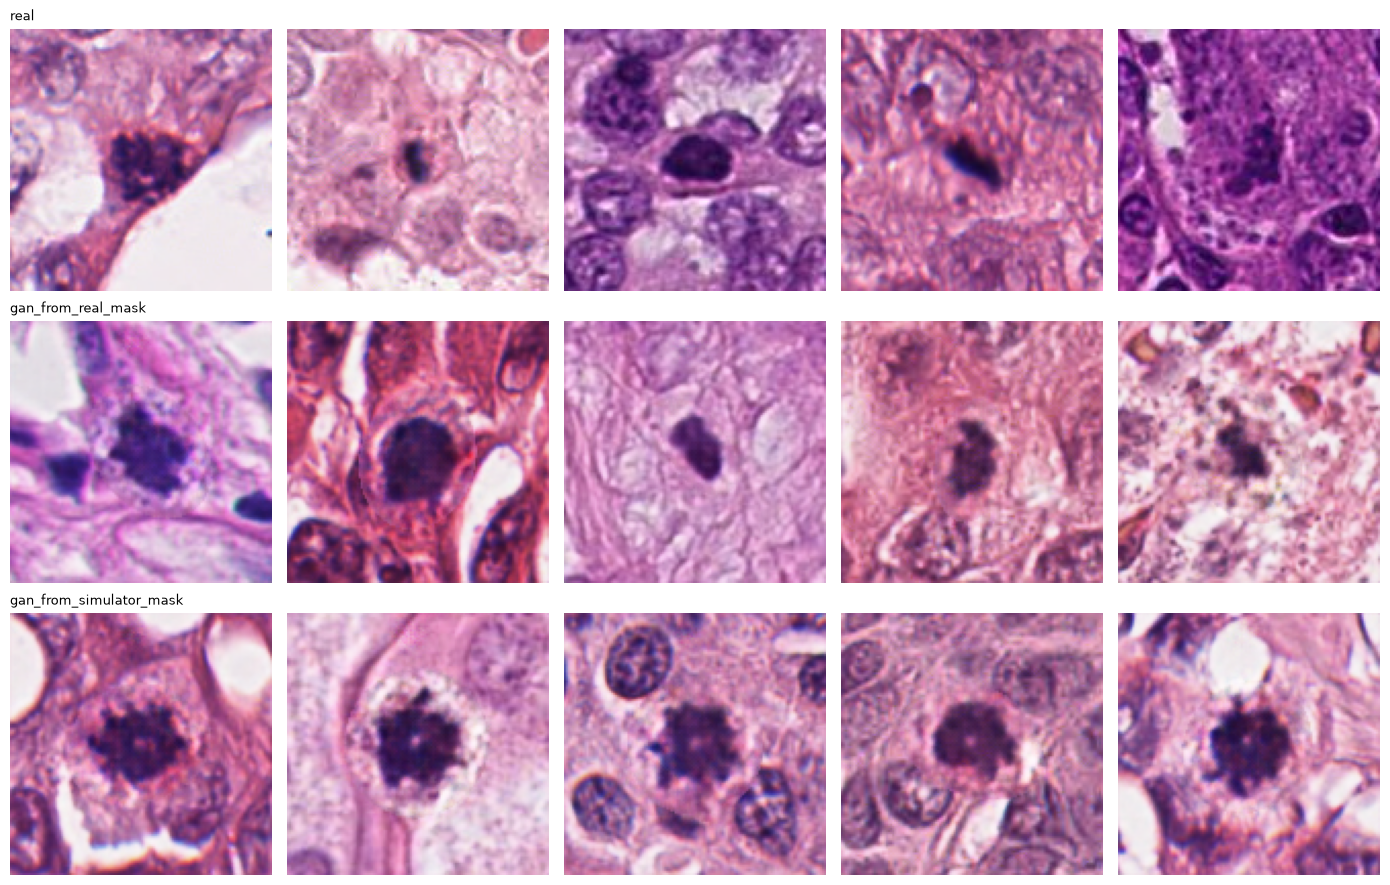

In [10]:
by_source = {"real": real_items, "gan_from_real_mask": gan_real_mask_items, "gan_from_simulator_mask": sim_items}
fig, axes = plt.subplots(3, 5, figsize=(14, 9))
for row, (source, items) in enumerate(by_source.items()):
    for col in range(5):
        ax = axes[row, col]
        if col < len(items):
            ax.imshow(items[col]["image"])
        ax.set_title(source if col == 0 else "", fontsize=9, loc="left")
        ax.axis("off")
plt.tight_layout()
plt.show()

## Scoring

Reads a SWAN results export -- one row per trial: `time,study,file,choice,
label,user_or_session` (see `human_experts_2nd_study.csv` for a real example). `file`
matches this notebook's own `study_id`, `label` is the rater's `real`/
`fake` judgment. Reports pooled accuracy, a per-rater breakdown (when the
export holds more than one `user_or_session`), and -- the point of this
notebook's extra `source` column -- fake accuracy broken out by *which*
kind of fake it was: a rater who reliably catches `gan_from_real_mask` but
not `gan_from_simulator_mask` (or vice versa) is a materially different
result than one flat "fake" number would show.

In [ ]:
SWAN_RESULTS_PATH = Path("../experiments/human_experts_study.csv")  # a SWAN results export for this study

with open(OUT_DIR / "answer_key.csv") as f:
    answer_key = {row["study_id"]: row for row in csv.DictReader(f)}

with open(SWAN_RESULTS_PATH) as f:
    trials = list(csv.DictReader(f))

unknown_files = sorted({t["file"] for t in trials} - answer_key.keys())
if unknown_files:
    print(f"{len(unknown_files)} file(s) in the SWAN export aren't in this study's answer_key.csv, "
          f"e.g. {unknown_files[0]!r} -- skipped (wrong answer_key.csv for this export?)")

unrated = sorted(answer_key.keys() - {t["file"] for t in trials})
if unrated:
    print(f"{len(unrated)} stimulus/stimuli from this study never appear in the SWAN export, e.g. {unrated[0]!r}")


def score(trial_rows):
    n_correct = n_total = 0
    for t in trial_rows:
        row = answer_key.get(t["file"])
        guess = t["label"].strip().lower()
        if row is None or guess not in ("real", "fake"):
            continue
        is_real = row["is_real"] == "True"
        n_total += 1
        n_correct += (guess == "real") == is_real
    return n_correct, n_total


def report(label, trial_rows):
    n_correct, n_total = score(trial_rows)
    print(f"{label}: {n_correct}/{n_total} ({100 * n_correct / max(n_total, 1):.1f}%)")


def trials_for_source(trial_rows, source):
    return [t for t in trial_rows if answer_key.get(t["file"], {}).get("source") == source]


print("=== pooled ===")
report("all raters, all sources", trials)
for source in ("real", "gan_from_real_mask", "gan_from_simulator_mask"):
    report(f"  source={source}", trials_for_source(trials, source))

raters = sorted({t["user_or_session"] for t in trials})
if len(raters) > 1:
    for rater in raters:
        rater_trials = [t for t in trials if t["user_or_session"] == rater]
        print(f"\n=== rater {rater} ===")
        report("all sources", rater_trials)
        for source in ("real", "gan_from_real_mask", "gan_from_simulator_mask"):
            report(f"  source={source}", trials_for_source(rater_trials, source))

=== pooled ===
all raters, all sources: 347/400 (86.8%)
  source=real: 166/200 (83.0%)
  source=gan_from_real_mask: 86/100 (86.0%)
  source=gan_from_simulator_mask: 95/100 (95.0%)

=== rater 6e286c3c-ba0d-4972-8980-6dba4777f694 ===
all sources: 174/200 (87.0%)
  source=real: 76/100 (76.0%)
  source=gan_from_real_mask: 49/50 (98.0%)
  source=gan_from_simulator_mask: 49/50 (98.0%)

=== rater de3bc3a5-95bf-42d3-95b1-5c4b516b6b68 ===
all sources: 173/200 (86.5%)
  source=real: 90/100 (90.0%)
  source=gan_from_real_mask: 37/50 (74.0%)
  source=gan_from_simulator_mask: 46/50 (92.0%)
